# Hierarchical ITS for staggered launches (event-study)

This notebook demonstrates `HierarchicalInterruptedTimeSeries`, a multi-unit ITS design where each unit (e.g. a product) has its **own** treatment time. Per-unit intercepts, **time trends**, covariate slopes and the launch "lift" are partially
pooled toward shared population-level hyperparameters, so sparse units borrow strength from well-observed ones and we recover a posterior over the population effect that can be used to forecast the impact of a *new* launch.

The model always includes **hierarchical (random) linear time trends** per unit, $\gamma_i \sim \mathcal{N}(\mu_\gamma, \sigma_\gamma)$, so that the baseline for each unit can drift over time rather than being a flat intercept. This is important for avoiding confounding between secular trends and the treatment effect.

Four effect parameterizations are available:

- `effect_type='instant'` &mdash; a single post-launch level shift per unit.
- `effect_type='saturation'` &mdash; a Hill (logistic-type) saturation curve: the effect ramps up smoothly after launch and asymptotes at a per-unit ceiling, rather than jumping instantly to its final size.
- `effect_type='event_study'` &mdash; dynamic effects across post-launch event-time bins.
- `effect_type='placebo'` &mdash; the event-study form extended with pre-launch leads as placebos.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pymc as pm

import causalpy as cp
from causalpy.pymc_models import HierarchicalITS

rng = np.random.default_rng(42)

## Shared simulation utilities

Each of the three model variants is designed to handle a different kind of
treatment effect, so in the sections below we simulate a **different** panel
for each one to show how faithfully it recovers the truth. The helpers below
build a panel of `N_PRODUCTS` products observed weekly over `T` weeks with
per-product intercepts, covariate slopes, shared seasonality, and a
user-supplied effect function `effect_fn(tau)` that returns the true causal
contribution for a given event time `tau = week - launch_week`.

In [2]:
N_PRODUCTS = 15
T = 200


def fourier_terms(t, period=52, K=2):
    cols = []
    for k in range(1, K + 1):
        cols.append(np.sin(2 * np.pi * k * t / period))
        cols.append(np.cos(2 * np.pi * k * t / period))
    return np.column_stack(cols)


def simulate_panel(effect_fn, seed, n_products=N_PRODUCTS, T=T):
    """Simulate a staggered-launch panel with a user-supplied effect function.

    ``effect_fn(tau, i)`` receives event time (weeks since launch) and the
    product index and returns the true causal contribution to sales.

    Each unit has its own linear time trend ``trend_i ~ N(0.01, 0.005)`` —
    small enough that the staggered design can separate it from the treatment
    effect, but large enough to exercise the model's time-trend component.
    """
    rng = np.random.default_rng(seed)
    alpha = rng.normal(50, 8, n_products)
    trend = rng.normal(0.01, 0.005, n_products)  # per-unit time trend
    gamma = rng.normal(0.15, 0.03, n_products)
    delta = rng.normal(-0.6, 0.1, n_products)
    launch_week = rng.integers(40, T - 80, n_products)

    week_idx = np.arange(T)
    season = fourier_terms(week_idx) @ np.array([6.0, -3.0, 2.0, -1.5])

    rows = []
    for i in range(n_products):
        emails = rng.normal(120, 25, T)
        price = rng.normal(20, 2, T)
        tau = week_idx - launch_week[i]
        effect = effect_fn(tau, i, rng)
        sales = (
            alpha[i]
            + trend[i] * week_idx  # linear time trend per unit
            + gamma[i] * emails
            + delta[i] * price
            + season
            + effect
            + rng.normal(0, 4, T)
        )
        rows.append(
            pd.DataFrame(
                {
                    "product": i,
                    "week_idx": week_idx,
                    "launch_week": launch_week[i],
                    "sales": sales,
                    "emails": emails,
                    "price": price,
                }
            )
        )
    return pd.concat(rows, ignore_index=True)

## Instant lift model

**DGP:** a flat post-launch step of size `lift_i ~ N(12, 4)`. Each product's effect is constant from the launch week onwards — the simplest causal story and the one the `instant` model is designed for.

Constructing the experiment only validates and prepares the data; `.fit()` runs the sampler and fills `result` (call `sample_prior_predictive()` first if you want prior checks, which then live in `prior_result`).

In [3]:
TRUE_MU_LIFT = 12.0
TRUE_SIGMA_LIFT = 4.0
_lift_rng = np.random.default_rng(7)
_lift_i = _lift_rng.normal(TRUE_MU_LIFT, TRUE_SIGMA_LIFT, N_PRODUCTS)


def instant_effect(tau, i, rng):
    return _lift_i[i] * (tau >= 0).astype(float)


df_instant = simulate_panel(instant_effect, seed=0)

result_instant = cp.HierarchicalInterruptedTimeSeries(
    data=df_instant,
    formula="sales ~ 0 + emails + price",
    unit_col="product",
    time_col="week_idx",
    treatment_time_col="launch_week",
    effect_type="instant",
    seasonality={"period": 52, "K": 2},
    model=HierarchicalITS(
        sample_kwargs={
            "draws": 1000,
            "tune": 1500,
            "chains": 4,
            "target_accept": 0.95,
            "random_seed": 42,
            "progressbar": False,
        }
    ),
).fit()

Initializing NUTS using jitter+adapt_diag...


Multiprocess sampling (4 chains in 4 jobs)


NUTS: [mu_alpha, sigma_alpha, z_alpha, mu_gamma, sigma_gamma, z_gamma, mu_beta, sigma_beta, z_beta, beta_season, mu_lift, sigma_lift, z_lift, sigma]


Sampling 4 chains for 1_500 tune and 1_000 draw iterations (6_000 + 4_000 draws total) took 32 seconds.


The rhat statistic is larger than 1.01 for some parameters. This indicates problems during sampling. See https://arxiv.org/abs/1903.08008 for details


The effective sample size per chain is smaller than 100 for some parameters.  A higher number is needed for reliable rhat and ess computation. See https://arxiv.org/abs/1903.08008 for details


... (2 outputs left out)

Sampling: [y_hat]


Sampling: [beta_season, mu_alpha, mu_beta, mu_gamma, mu_lift, sigma, sigma_alpha, sigma_beta, sigma_gamma, sigma_lift, y_hat, z_alpha, z_beta, z_gamma, z_lift]


Sampling: [y_hat]


Sampling: [y_hat]


Hierarchical ITS (staggered launch)
Formula: sales ~ 0 + emails + price
Effect type: instant
Units: 15
E[mu_lift] = 11.2   E[sigma_lift] = 2.63


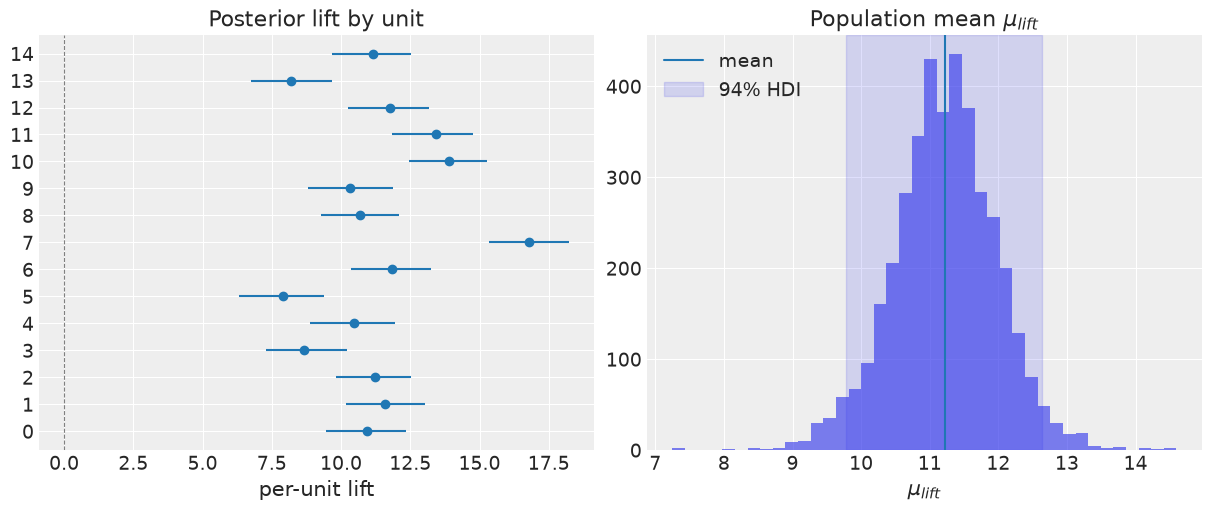

In [4]:
result_instant.summary()
result_instant.plot();

### Inspecting the fitted model

Every fitted `HierarchicalInterruptedTimeSeries` exposes the full PyMC posterior via `result.idata` (an xarray `DataTree`). From here you can visualise the model graph, check convergence, extract effect summaries, and compute Bayesian R&sup2;.

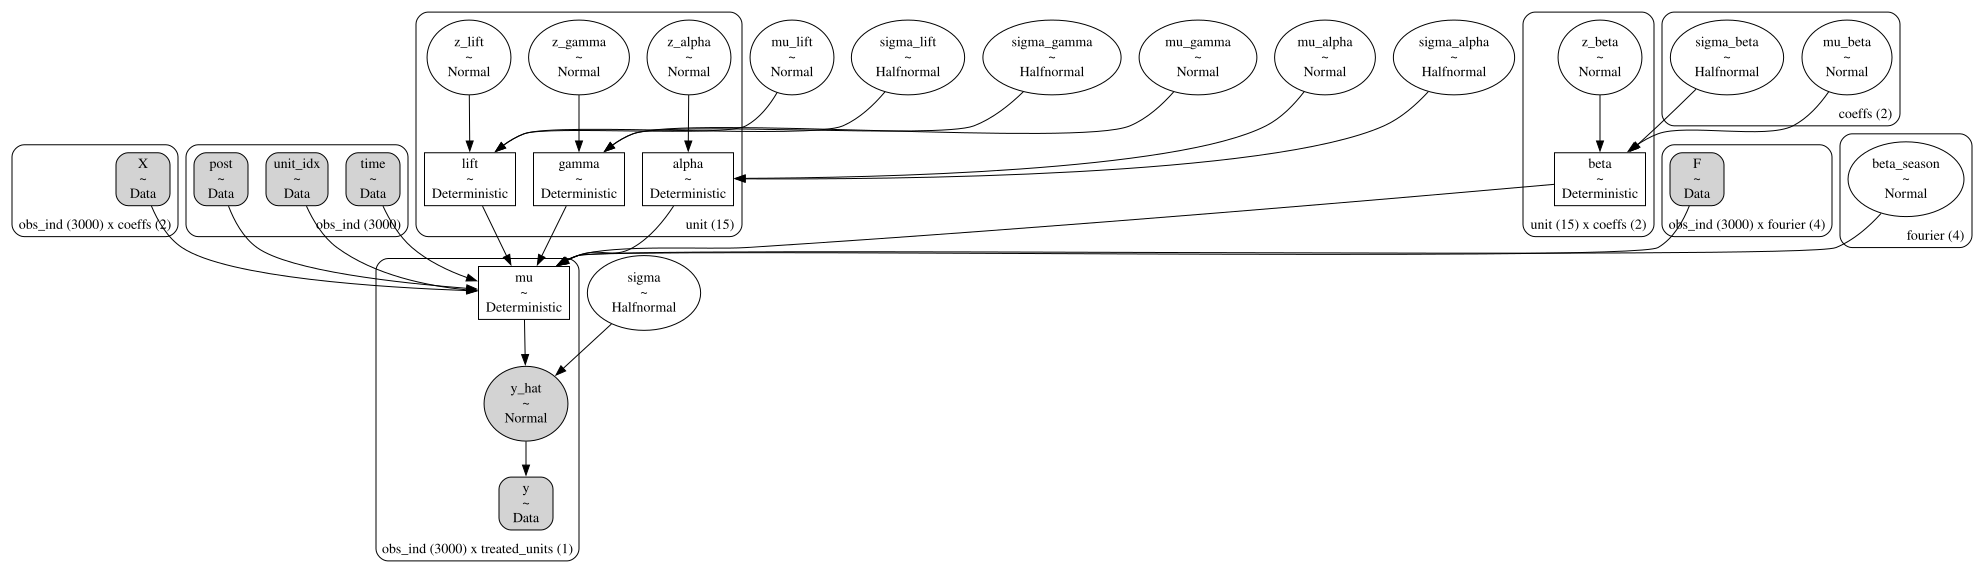

In [5]:
# The model DAG — shows all hierarchical parameters and their dependencies
pm.model_to_graphviz(result_instant.model)

In [6]:
import arviz as az

# Convergence diagnostics for key hyperparameters: R-hat near 1.0 and
# large ESS (effective sample size) indicate healthy sampling.
az.summary(
    result_instant.idata,
    var_names=["mu_lift", "sigma_lift", "mu_gamma", "sigma_gamma", "sigma"],
    ci_kind="hdi",
    ci_prob=0.94,
)

,mean,sd,hdi94_lb,hdi94_ub,ess_bulk,ess_tail,r_hat,mcse_mean,mcse_sd
mu_lift,11.22,0.75,9.8,13,754,1259,1.00,0.027,0.019
sigma_lift,2.63,0.61,1.6,3.8,1160,1759,1.00,0.018,0.014
mu_gamma,0.734,0.167,0.42,1.1,2972,2808,1.00,0.0031,0.0028
sigma_gamma,0.32,0.206,0.00017,0.66,634,905,1.01,0.0077,0.0038
sigma,3.973,0.051,3.9,4.1,4410,3063,1.00,0.00076,0.00078


In [7]:
# effect_summary() reports the causal effect on the outcome scale:
# observed minus counterfactual (launch effect switched off), pooled over every
# post-launch product-week. `average` is the mean lift per product-week,
# `cumulative` the total incremental sales across all products, and the
# relative columns express both as a % of the counterfactual.
es = result_instant.effect_summary()
display(es.table)
print(es.text)

# `window` selects an event-time range (weeks since launch, inclusive) and
# `treated_unit` restricts the summary to a single product.
display(result_instant.effect_summary(window=(0, 12), cumulative=False).table)

# parameter_summary() reports the population-level model parameters instead:
# mu_lift is the expected lift for a typical product, sigma_lift the spread
# in lift across products.
display(result_instant.parameter_summary())

,mean,median,hdi_lower,hdi_upper,p_gt_0,relative_mean,relative_hdi_lower,relative_hdi_upper
average,11.036149,11.040499,10.527293,11.574142,1.0,19.039477,17.918533,20.066419
cumulative,18617.983829,18625.321645,17759.543497,19525.577677,1.0,19.039477,17.918533,20.066419


Post-period: Hierarchical ITS (staggered launch), effect_type='instant', 15 unit(s), 1687 unit-period observations (event-time window 'post').
Average effect per unit-period: 11.04 (95% HDI [10.53, 11.57]), P(effect > 0) = 1.00; 19.0% relative to the counterfactual.
Cumulative effect (all rows): 18617.98 (95% HDI [17759.54, 19525.58]), P(effect > 0) = 1.00; 19.0% relative to the counterfactual.


,mean,median,hdi_lower,hdi_upper,p_gt_0,relative_mean,relative_hdi_lower,relative_hdi_upper
average,11.19095,11.192291,10.844337,11.530423,1.0,19.302462,18.592402,20.003987


,mean,hdi_95_low,hdi_95_high,prob_positive
parameter,,,,
mu_lift,11.220471,9.620987,12.620848,1.0
sigma_lift,2.630263,1.533955,3.806249,1.0


In [8]:
# Bayesian R² — how much variance in the outcome is explained by the model.
result_instant.result.score

unit_0_r2        0.892826
unit_0_r2_std    0.001268
dtype: float64

### Predictive distribution for a *new* launch

Because the model has a posterior over the population hyperparameters, we can sample the lift we would expect from a yet-unobserved product.

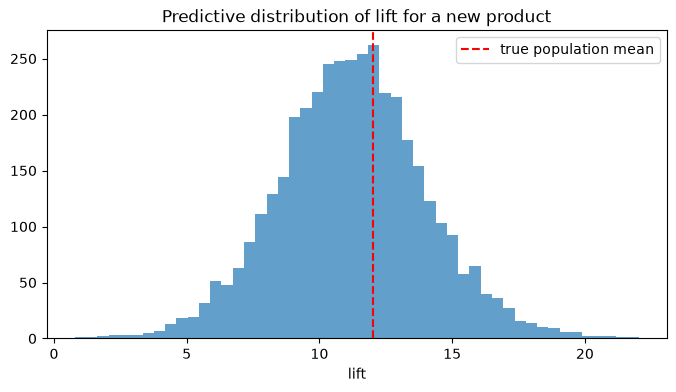

In [9]:
new_lift = result_instant.predictive_for_new_unit(size=4000, random_seed=0)
fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(new_lift, bins=50, alpha=0.7)
ax.axvline(TRUE_MU_LIFT, color="red", ls="--", label="true population mean")
ax.set_title("Predictive distribution of lift for a new product")
ax.set_xlabel("lift")
ax.legend()
plt.show()

### Observed vs counterfactual (single unit)

The fitted experiment stores three key objects for causal reasoning:

- **`result.result.observed_pred`** &mdash; posterior draws of the expected outcome `mu` under the *actual* design (with treatment effect switched on), with dimensions `(chain, draw, obs_ind, treated_units)`.
- **`result.result.counterfactual_pred`** &mdash; the same under the counterfactual design (treatment effect zeroed out &mdash; what would have happened without launch).
- **`result.result.impact`** &mdash; `observed - counterfactual`, the posterior of the causal effect at every product-week, with dimensions `(chain, draw, obs_ind)`. `effect_summary()` aggregates exactly this.

The `plot_unit()` method visualises all three for a single product.

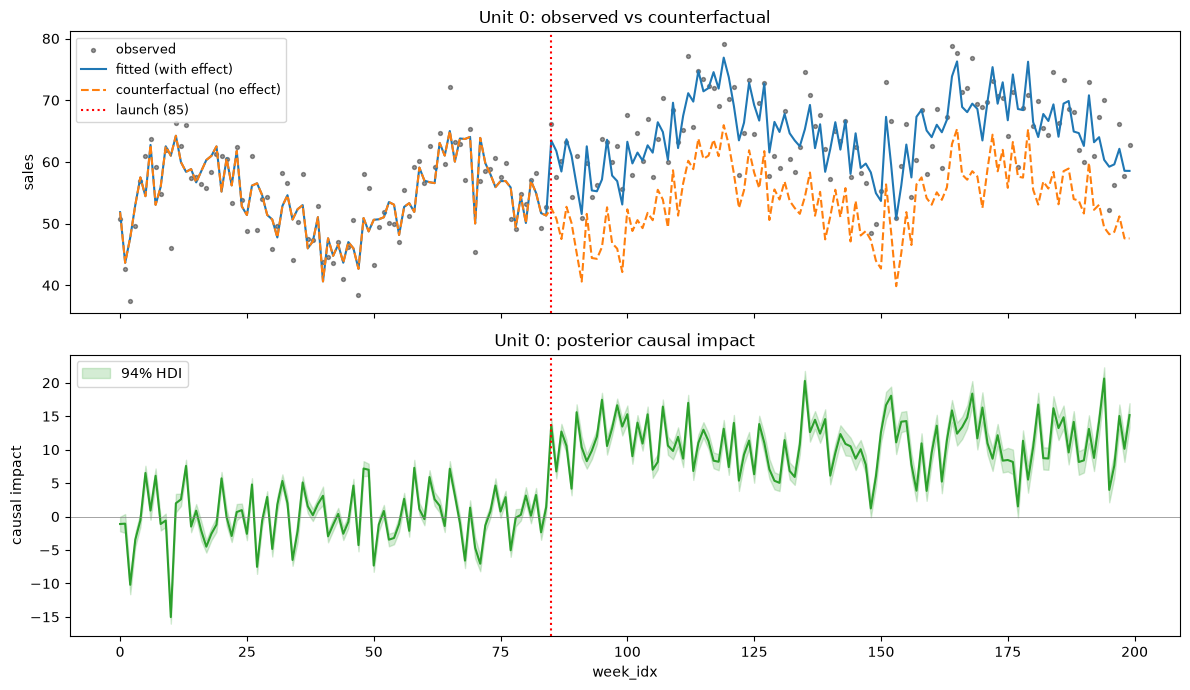

In [10]:
result_instant.plot_unit(unit_id=0)
plt.show()

## Saturation (Hill-curve) model

**DGP:** rather than an instant step, the true effect follows a **Hill (logistic-type) saturation curve** in event time — it ramps up smoothly after launch and asymptotes at a per-unit ceiling `L_i`, reaching half of that ceiling after `k_i` weeks:

$$
\text{effect}_i(\tau) = L_i \cdot \frac{\tau^s}{k_i^s + \tau^s}, \qquad \tau = \text{week} - \text{launch\_week} \ge 0
$$

This is the same functional form used for diminishing-returns / adstock saturation in media-mix models — here the "dose" is simply time-since-launch. It's a much closer description of how adoption, distribution build and awareness actually accumulate after a real launch than an instant jump. `effect_type='saturation'` fits `L_i` and `k_i` hierarchically per unit (log scale, non-centered); the Hill exponent `s` (curve sharpness) is a single shared population parameter.

In [11]:
def hill(x, k, s):
    """Hill (logistic-type) saturation curve, x clipped to [0, inf)."""
    x = np.clip(np.asarray(x, dtype=float), 0, None)
    return x**s / (k**s + x**s)


TRUE_L_MEAN = 14.0  # ceiling lift, population mean
TRUE_L_SD_LOG = 0.15  # per-unit heterogeneity (log scale)
TRUE_K_MEAN = 8.0  # half-saturation time (weeks), population mean
TRUE_K_SD_LOG = 0.15
TRUE_S = 2.5  # Hill exponent (shared across units)

_sat_rng = np.random.default_rng(13)
_L_i = np.exp(_sat_rng.normal(np.log(TRUE_L_MEAN), TRUE_L_SD_LOG, N_PRODUCTS))
_k_i = np.exp(_sat_rng.normal(np.log(TRUE_K_MEAN), TRUE_K_SD_LOG, N_PRODUCTS))


def saturation_effect(tau, i, rng):
    return _L_i[i] * hill(tau, _k_i[i], TRUE_S)


df_saturation = simulate_panel(saturation_effect, seed=3)

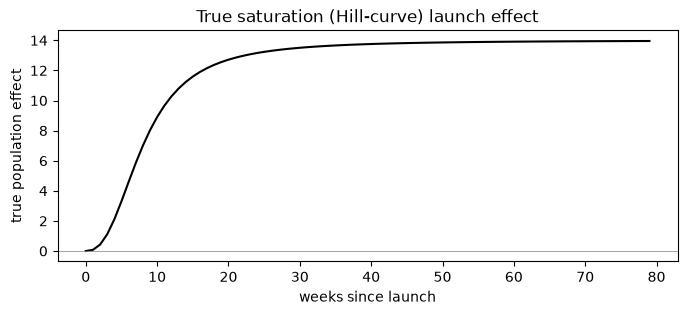

In [12]:
# Show the true population saturation curve we expect to recover.
tau_grid = np.arange(0, 80)
fig, ax = plt.subplots(figsize=(8, 3))
ax.plot(tau_grid, TRUE_L_MEAN * hill(tau_grid, TRUE_K_MEAN, TRUE_S), color="black")
ax.axhline(0, color="grey", lw=0.5)
ax.set_xlabel("weeks since launch")
ax.set_ylabel("true population effect")
ax.set_title("True saturation (Hill-curve) launch effect")
plt.show()

In [13]:
result_saturation = cp.HierarchicalInterruptedTimeSeries(
    data=df_saturation,
    formula="sales ~ 0 + emails + price",
    unit_col="product",
    time_col="week_idx",
    treatment_time_col="launch_week",
    effect_type="saturation",
    seasonality={"period": 52, "K": 2},
    model=HierarchicalITS(
        sample_kwargs={
            "draws": 1000,
            "tune": 1500,
            "chains": 4,
            "target_accept": 0.95,
            "random_seed": 42,
            "progressbar": False,
        }
    ),
).fit()

Initializing NUTS using jitter+adapt_diag...


Multiprocess sampling (4 chains in 4 jobs)


NUTS: [mu_alpha, sigma_alpha, z_alpha, mu_gamma, sigma_gamma, z_gamma, mu_beta, sigma_beta, z_beta, beta_season, mu_logL, sigma_logL, z_logL, mu_logk, sigma_logk, z_logk, s, sigma]


Sampling 4 chains for 1_500 tune and 1_000 draw iterations (6_000 + 4_000 draws total) took 121 seconds.


The rhat statistic is larger than 1.01 for some parameters. This indicates problems during sampling. See https://arxiv.org/abs/1903.08008 for details


Sampling: [y_hat]


Sampling: [y_hat]


Sampling: [y_hat]


Sampling: [beta_season, mu_alpha, mu_beta, mu_gamma, mu_logL, mu_logk, s, sigma, sigma_alpha, sigma_beta, sigma_gamma, sigma_logL, sigma_logk, y_hat, z_alpha, z_beta, z_gamma, z_logL, z_logk]


Sampling: [y_hat]


Sampling: [y_hat]


Hierarchical ITS (staggered launch)
Formula: sales ~ 0 + emails + price
Effect type: saturation
Units: 15
Median-unit L (ceiling lift) = 14.6   median-unit k (half-saturation time) = 8.46   s (Hill exponent) = 2.55


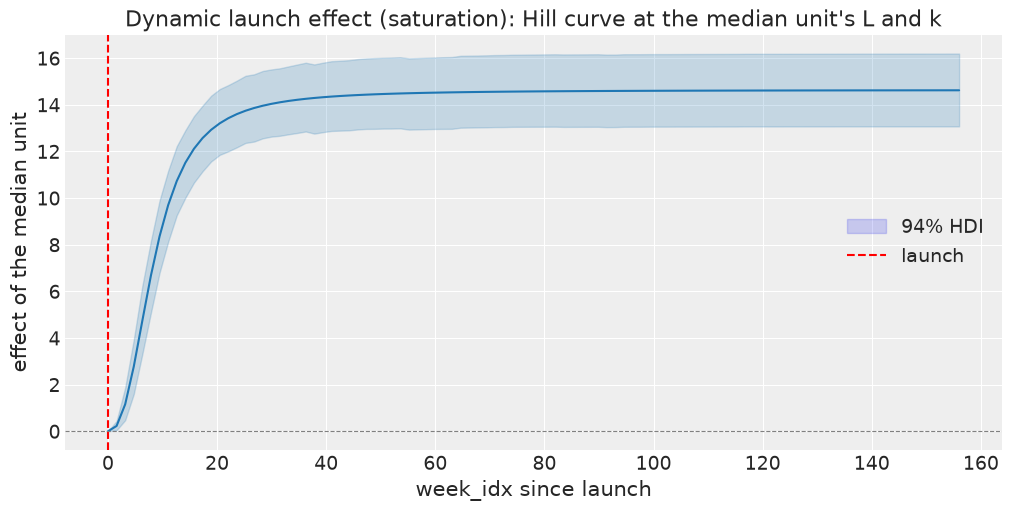

In [14]:
result_saturation.summary()
result_saturation.plot();

### Convergence diagnostics and effect summary

`L` and `k` are fit hierarchically on the log scale (`mu_logL`/`sigma_logL`, `mu_logk`/`sigma_logk`); `s` is a single shared parameter. `effect_summary()` reports the realised effect on sales &mdash; the average and cumulative post-launch lift, which here includes the ramp-up weeks before each product reaches its ceiling. `parameter_summary()` reports the ceiling lift and half-saturation time of the *median* product (`exp(mu_logL)`, `exp(mu_logk)`) and the shared Hill exponent, which describe the *shape* of the curve rather than the realised effect. Because `L` is log-normal, this variant assumes the launch raises sales; use the event-study variant if the effect could be negative.

In [15]:
# R-hat near 1.0 and large ESS indicate healthy sampling.
display(
    az.summary(
        result_saturation.idata,
        var_names=[
            "mu_logL",
            "sigma_logL",
            "mu_logk",
            "sigma_logk",
            "s",
            "mu_gamma",
            "sigma_gamma",
            "sigma",
        ],
        ci_kind="hdi",
        ci_prob=0.94,
    )
)

# Realised effect on sales (outcome scale)
es = result_saturation.effect_summary()
display(es.table)
print(es.text)

# Population-level Hill-curve parameters
display(result_saturation.parameter_summary())

,mean,sd,hdi94_lb,hdi94_ub,ess_bulk,ess_tail,r_hat,mcse_mean,mcse_sd
mu_logL,2.682,0.057,2.6,2.8,1406,1938,1.00,0.0015,0.00096
sigma_logL,0.177,0.044,0.11,0.26,1678,2210,1.00,0.001,0.00075
mu_logk,2.132,0.079,2,2.3,2280,2638,1.00,0.0017,0.0015
sigma_logk,0.237,0.077,0.1,0.38,1494,2079,1.00,0.0019,0.0013
s,2.551,0.266,2.1,3,5278,3373,1.00,0.0037,0.0042
mu_gamma,0.631,0.21,0.25,1,4343,3394,1.00,0.0032,0.0034
sigma_gamma,0.31,0.206,0.00021,0.65,1184,1735,1.00,0.0057,0.0034
sigma,4.099,0.054,4,4.2,8681,2788,1.00,0.00058,0.001


,mean,median,hdi_lower,hdi_upper,p_gt_0,relative_mean,relative_hdi_lower,relative_hdi_upper
average,13.418501,13.410646,12.727208,14.08437,1.0,23.57667,22.089511,25.034714
cumulative,23791.002377,23777.076214,22565.340627,24971.58864,1.0,23.57667,22.089511,25.034714


Post-period: Hierarchical ITS (staggered launch), effect_type='saturation', 15 unit(s), 1773 unit-period observations (event-time window 'post').
Average effect per unit-period: 13.42 (95% HDI [12.73, 14.08]), P(effect > 0) = 1.00; 23.6% relative to the counterfactual.
Cumulative effect (all rows): 23791.00 (95% HDI [22565.34, 24971.59]), P(effect > 0) = 1.00; 23.6% relative to the counterfactual.


,mean,hdi_95_low,hdi_95_high,prob_positive
parameter,,,,
median-unit L (ceiling lift),14.632710,12.990857,16.281304,1.0
median-unit k (half-saturation time),8.455277,7.190469,9.806495,1.0
s (Hill exponent),2.550591,2.038021,3.071065,1.0


### Population predictive curve for a new unit

For `effect_type='saturation'`, `predictive_for_new_unit` returns a `(draws, 3)` array of `[L, k, s]` samples for a hypothetical new product. Turning each draw into a full Hill curve and overlaying the resulting predictive band on the true population curve shows how well the model recovers both *how big* (`L`) and *how fast* (`k`) the effect is.

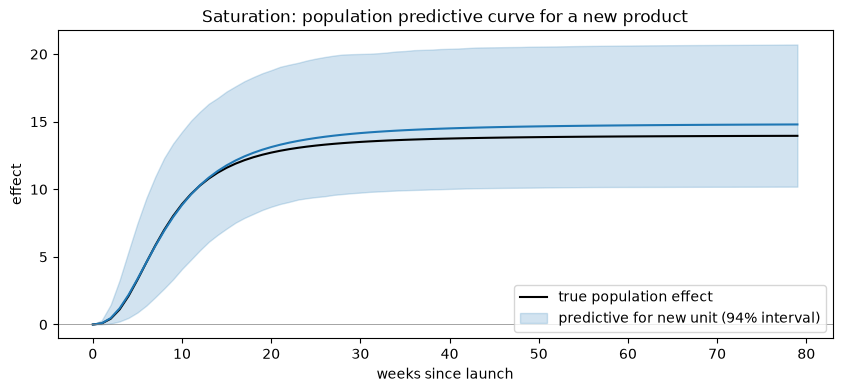

In [16]:
new_sat = result_saturation.predictive_for_new_unit(size=4000, random_seed=0)
# new_sat shape: (4000, 3) -> columns [L, k, s]
tau_grid = np.arange(0, 80)
L_draws, k_draws, s_draws = new_sat[:, 0], new_sat[:, 1], new_sat[:, 2]
curves = L_draws[:, None] * hill(tau_grid[None, :], k_draws[:, None], s_draws[:, None])
pred_mean = curves.mean(axis=0)
pred_lo = np.percentile(curves, 3, axis=0)
pred_hi = np.percentile(curves, 97, axis=0)

fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(
    tau_grid,
    TRUE_L_MEAN * hill(tau_grid, TRUE_K_MEAN, TRUE_S),
    color="black",
    label="true population effect",
)
ax.fill_between(
    tau_grid,
    pred_lo,
    pred_hi,
    color="C0",
    alpha=0.2,
    label="predictive for new unit (94% interval)",
)
ax.plot(tau_grid, pred_mean, color="C0")
ax.axhline(0, color="grey", lw=0.5)
ax.set_xlabel("weeks since launch")
ax.set_ylabel("effect")
ax.set_title("Saturation: population predictive curve for a new product")
ax.legend()
plt.show()

### Observed vs counterfactual (single unit)

Same three objects as the instant model (`observed_pred`, `counterfactual_pred`, `impact`) — but now the counterfactual gap traces out the shape of the Hill curve, ramping up after launch, rather than jumping instantly to a constant lift.

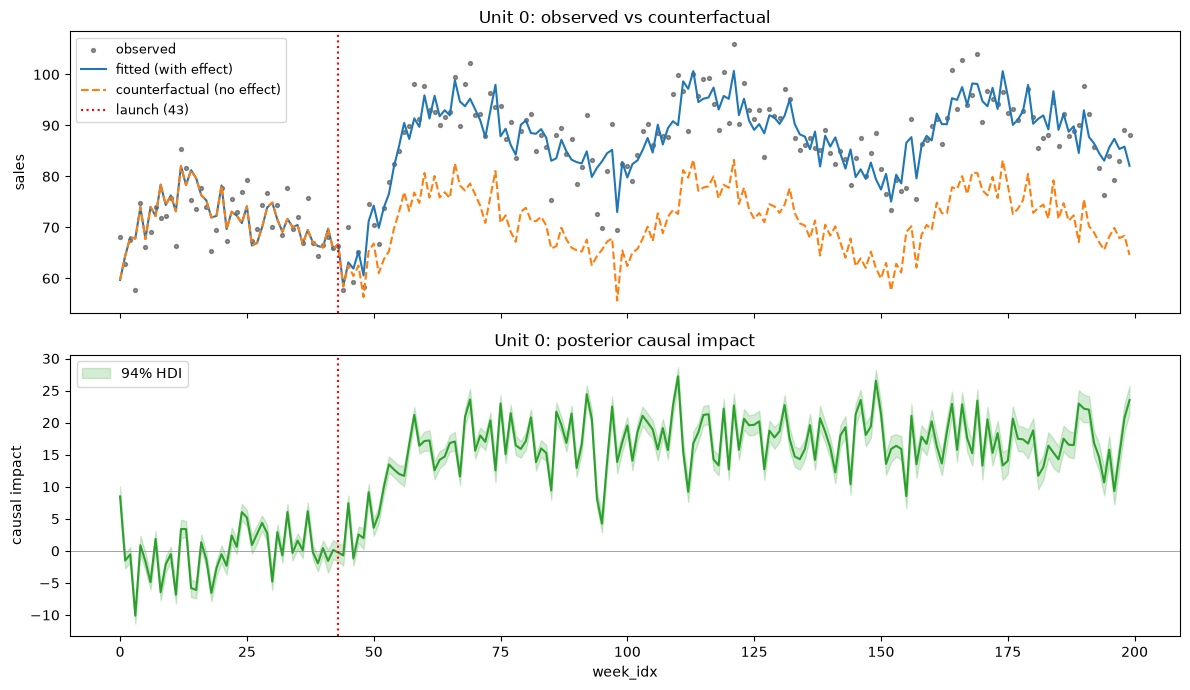

In [17]:
result_saturation.plot_unit(unit_id=0)
plt.show()

## Event-study (dynamic) model

**DGP:** a realistic launch curve — awareness ramps up over the first few weeks, peaks around week 8, then decays toward a lower long-run level as novelty wears off. A single "instant" lift would average this over time and miss the story entirely; the event-study variant estimates a separate population effect per post-launch bin and should trace out the true curve.

In [18]:
TRUE_MU_AMP = 12.0
TRUE_SIGMA_AMP = 3.0
_amp_rng = np.random.default_rng(11)
_amp_i = _amp_rng.normal(TRUE_MU_AMP, TRUE_SIGMA_AMP, N_PRODUCTS)


def launch_shape(tau):
    """Ramp-up, peak around week 8, decay toward ~40% long-run level."""
    tau = np.asarray(tau, dtype=float)
    return np.where(
        tau < 0,
        0.0,
        (1 - np.exp(-tau / 3.0)) * (0.4 + 0.6 * np.exp(-((tau - 8.0) ** 2) / 80.0)),
    )


def dynamic_effect(tau, i, rng):
    return _amp_i[i] * launch_shape(tau)


df_event = simulate_panel(dynamic_effect, seed=1)

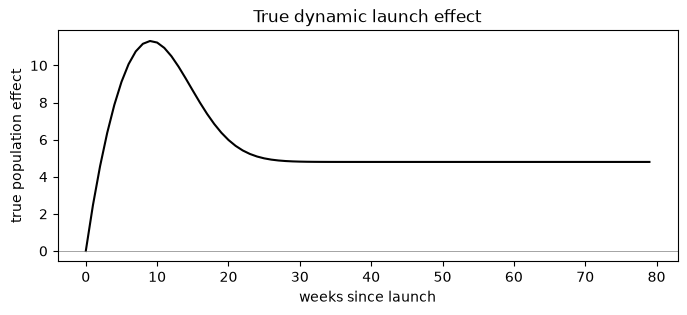

In [19]:
# Show the true population event-time curve we expect to recover.
tau_grid = np.arange(0, 80)
fig, ax = plt.subplots(figsize=(8, 3))
ax.plot(tau_grid, TRUE_MU_AMP * launch_shape(tau_grid), color="black")
ax.axhline(0, color="grey", lw=0.5)
ax.set_xlabel("weeks since launch")
ax.set_ylabel("true population effect")
ax.set_title("True dynamic launch effect")
plt.show()

In [20]:
result_event = cp.HierarchicalInterruptedTimeSeries(
    data=df_event,
    formula="sales ~ 0 + emails + price",
    unit_col="product",
    time_col="week_idx",
    treatment_time_col="launch_week",
    effect_type="event_study",
    bin_edges=[0, 4, 8, 12, 16, 20, 26, 39, 52, 78, 10000],
    seasonality={"period": 52, "K": 2},
    model=HierarchicalITS(
        sample_kwargs={
            "draws": 1000,
            "tune": 1500,
            "chains": 4,
            "target_accept": 0.95,
            "random_seed": 42,
            "progressbar": False,
        }
    ),
).fit()

Initializing NUTS using jitter+adapt_diag...


Multiprocess sampling (4 chains in 4 jobs)


NUTS: [mu_alpha, sigma_alpha, z_alpha, mu_gamma, sigma_gamma, z_gamma, mu_beta, sigma_beta, z_beta, beta_season, mu_delta, sigma_delta, z_delta, sigma]


Sampling 4 chains for 1_500 tune and 1_000 draw iterations (6_000 + 4_000 draws total) took 32 seconds.


Sampling: [y_hat]


Sampling: [y_hat]


Sampling: [y_hat]


Sampling: [beta_season, mu_alpha, mu_beta, mu_delta, mu_gamma, sigma, sigma_alpha, sigma_beta, sigma_delta, sigma_gamma, y_hat, z_alpha, z_beta, z_delta, z_gamma]


Sampling: [y_hat]


Sampling: [y_hat]


Hierarchical ITS (staggered launch)
Formula: sales ~ 0 + emails + price
Effect type: event_study
Units: 15
  [0,4)               mu_delta = +4.04
  [4,8)               mu_delta = +8.89
  [8,12)              mu_delta = +11.8
  [12,16)             mu_delta = +9.83
  [16,20)             mu_delta = +7.09
  [20,26)             mu_delta = +5.47
  [26,39)             mu_delta = +4.85
  [39,52)             mu_delta = +5.08
  [52,78)             mu_delta = +5.03
  [78,10000)          mu_delta = +5.13


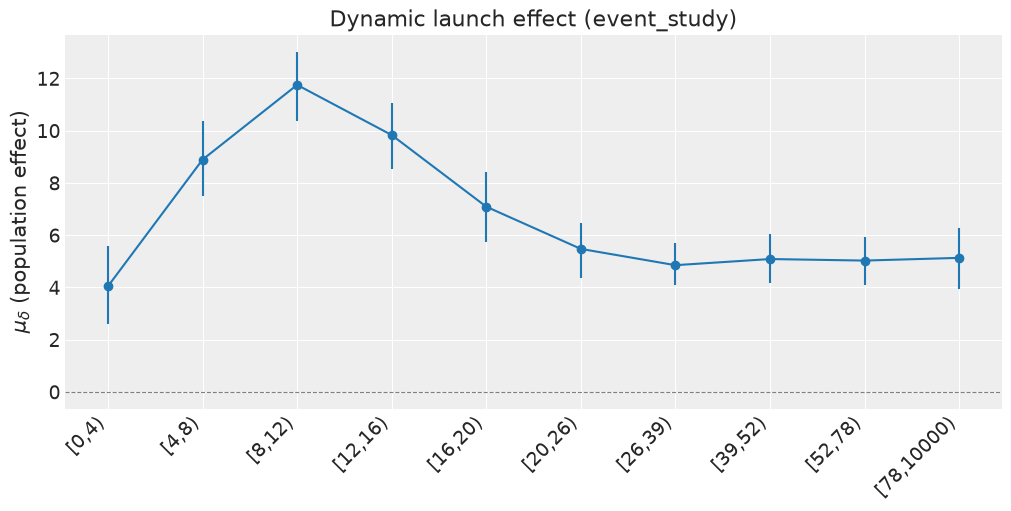

In [21]:
result_event.summary()
result_event.plot();

### Population predictive for a new unit

For the event-study variant, `predictive_for_new_unit` returns a `(draws, n_bins)` array &mdash; one draw from $\mathcal{N}(\mu_\delta, \sigma_\delta)$ per bin per posterior sample. We can overlay the posterior mean and HDI on the true population curve to see how well the model recovers the dynamic launch shape.

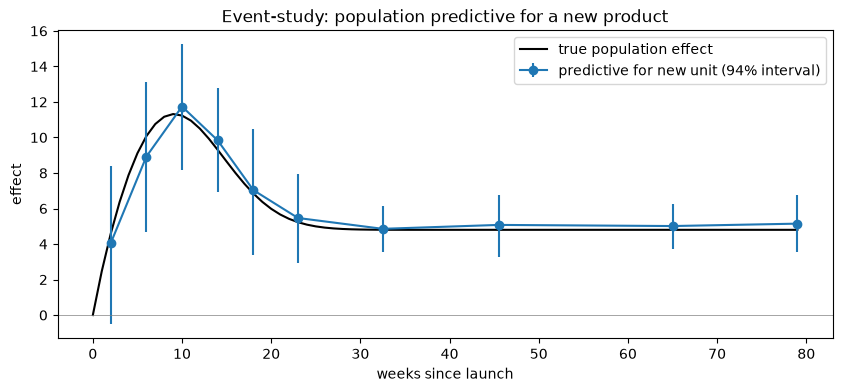

In [22]:
new_delta = result_event.predictive_for_new_unit(size=4000, random_seed=0)
# new_delta shape: (4000, n_bins)
bin_edges = [0, 4, 8, 12, 16, 20, 26, 39, 52, 78, 10000]
bin_mids = [
    0.5 * (bin_edges[k] + min(bin_edges[k + 1], 80)) for k in range(len(bin_edges) - 1)
]

fig, ax = plt.subplots(figsize=(10, 4))
# True curve
tau_grid = np.arange(0, 80)
ax.plot(
    tau_grid,
    TRUE_MU_AMP * launch_shape(tau_grid),
    color="black",
    label="true population effect",
)
# Posterior predictive for new unit
pred_mean = new_delta.mean(axis=0)
pred_lo = np.percentile(new_delta, 3, axis=0)
pred_hi = np.percentile(new_delta, 97, axis=0)
ax.errorbar(
    bin_mids,
    pred_mean,
    yerr=np.vstack([pred_mean - pred_lo, pred_hi - pred_mean]),
    fmt="o-",
    color="C0",
    label="predictive for new unit (94% interval)",
)
ax.axhline(0, color="grey", lw=0.5)
ax.set_xlabel("weeks since launch")
ax.set_ylabel("effect")
ax.set_title("Event-study: population predictive for a new product")
ax.legend()
plt.show()

## Placebo (lead/lag) model

**DGP:** we generate *two* panels from the **same random seed** (so the noise, covariates and launch weeks are identical) but with different treatment effects:

1. **With anticipation** — the ramp/peak/decay post-launch curve plus a
   deliberate pre-launch linear build-up over the 8 weeks before launch
   (e.g. a pre-order period). The placebo bins in `[-8, -4)` and `[-4, 0)`
   should absorb this and the automatic check should **fail**.
2. **Without anticipation** — the same post-launch dynamics but strictly zero
   before launch. The placebo bins should be indistinguishable from zero and
   the check should **pass**.

Because the only difference between the two panels is the anticipation component, the contrast isolates exactly what the placebo test is designed to detect.

In [23]:
def anticipation_effect(tau, i, rng):
    """Dynamic post-launch effect + pre-launch build-up over 8 weeks."""
    post = _amp_i[i] * launch_shape(tau)
    tau_arr = np.asarray(tau, dtype=float)
    lead = np.where(
        (tau_arr >= -8) & (tau_arr < 0),
        _amp_i[i] * 0.4 * (tau_arr + 8) / 8.0,  # linear ramp up to ~40% of amp
        0.0,
    )
    return post + lead


def clean_dynamic_effect(tau, i, rng):
    """Same post-launch dynamics, but strictly zero before launch."""
    return _amp_i[i] * launch_shape(tau)


# Same seed → identical noise; only difference is the anticipation component
df_placebo_bad = simulate_panel(anticipation_effect, seed=2)
df_placebo_clean = simulate_panel(clean_dynamic_effect, seed=2)


def make_placebo_model():
    return HierarchicalITS(
        sample_kwargs={
            "draws": 1000,
            "tune": 1500,
            "chains": 4,
            "target_accept": 0.97,
            "random_seed": 42,
            "progressbar": False,
        }
    )


placebo_kwargs = {
    "formula": "sales ~ 0 + emails + price",
    "unit_col": "product",
    "time_col": "week_idx",
    "treatment_time_col": "launch_week",
    "effect_type": "placebo",
    "bin_edges": [0, 4, 8, 12, 16, 20, 26, 39, 52, 78, 10000],
    "placebo_edges": [-26, -20, -16, -12, -8, -4, 0],
    "seasonality": {"period": 52, "K": 2},
}

In [24]:
result_placebo_bad = cp.HierarchicalInterruptedTimeSeries(
    data=df_placebo_bad, model=make_placebo_model(), **placebo_kwargs
).fit()

Initializing NUTS using jitter+adapt_diag...


Multiprocess sampling (4 chains in 4 jobs)


NUTS: [mu_alpha, sigma_alpha, z_alpha, mu_gamma, sigma_gamma, z_gamma, mu_beta, sigma_beta, z_beta, beta_season, mu_delta, sigma_delta, z_delta, sigma]


Sampling 4 chains for 1_500 tune and 1_000 draw iterations (6_000 + 4_000 draws total) took 79 seconds.


The rhat statistic is larger than 1.01 for some parameters. This indicates problems during sampling. See https://arxiv.org/abs/1903.08008 for details


The effective sample size per chain is smaller than 100 for some parameters.  A higher number is needed for reliable rhat and ess computation. See https://arxiv.org/abs/1903.08008 for details


... (2 outputs left out)

Sampling: [y_hat]


Sampling: [beta_season, mu_alpha, mu_beta, mu_delta, mu_gamma, sigma, sigma_alpha, sigma_beta, sigma_delta, sigma_gamma, y_hat, z_alpha, z_beta, z_delta, z_gamma]


Sampling: [y_hat]


Sampling: [y_hat]


=== Panel WITH anticipation (placebo check should FAIL) ===
Hierarchical ITS (staggered launch)
Formula: sales ~ 0 + emails + price
Effect type: placebo
Units: 15
  pre[-26,-20)        mu_delta = -0.364
  pre[-20,-16)        mu_delta = +0.689
  pre[-16,-12)        mu_delta = -0.29
  pre[-12,-8)         mu_delta = +0.53
  pre[-8,-4)          mu_delta = +0.343
  pre[-4,0)           mu_delta = +3.32
  post[0,4)           mu_delta = +2.97
  post[4,8)           mu_delta = +9.3
  post[8,12)          mu_delta = +11.3
  post[12,16)         mu_delta = +10.2
  post[16,20)         mu_delta = +7.41
  post[20,26)         mu_delta = +5.74
  post[26,39)         mu_delta = +4.86
  post[39,52)         mu_delta = +4.32
  post[52,78)         mu_delta = +4.35
  post[78,10000)      mu_delta = +4
Placebo check: FAIL (evidence of anticipation): 5/6 pre-launch bins contain 0 within the 94% HDI (median HDI width 2.49; wide intervals are weak evidence either way)


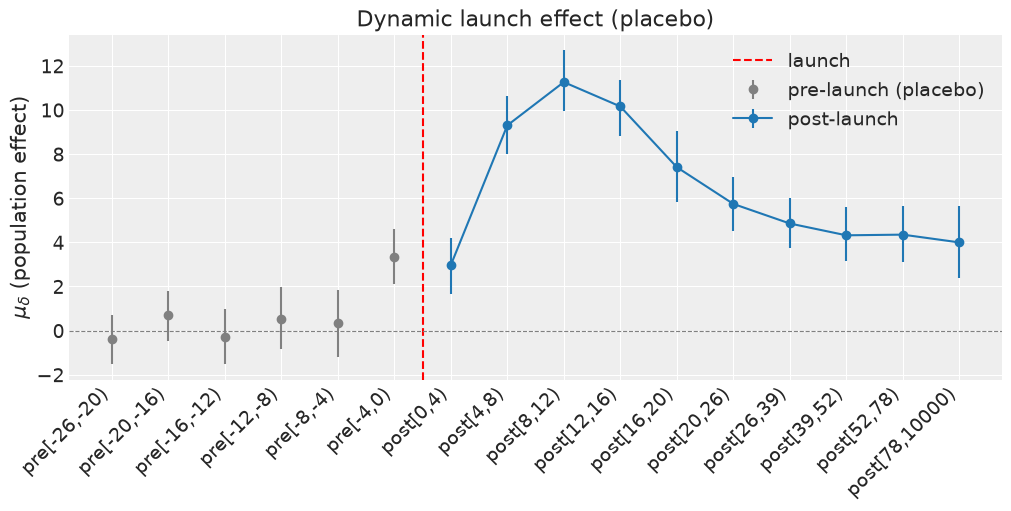

In [25]:
print("=== Panel WITH anticipation (placebo check should FAIL) ===")
result_placebo_bad.summary()
result_placebo_bad.plot();

In [26]:
result_placebo_ok = cp.HierarchicalInterruptedTimeSeries(
    data=df_placebo_clean, model=make_placebo_model(), **placebo_kwargs
).fit()

Initializing NUTS using jitter+adapt_diag...


Multiprocess sampling (4 chains in 4 jobs)


NUTS: [mu_alpha, sigma_alpha, z_alpha, mu_gamma, sigma_gamma, z_gamma, mu_beta, sigma_beta, z_beta, beta_season, mu_delta, sigma_delta, z_delta, sigma]


Sampling 4 chains for 1_500 tune and 1_000 draw iterations (6_000 + 4_000 draws total) took 62 seconds.


The rhat statistic is larger than 1.01 for some parameters. This indicates problems during sampling. See https://arxiv.org/abs/1903.08008 for details


The effective sample size per chain is smaller than 100 for some parameters.  A higher number is needed for reliable rhat and ess computation. See https://arxiv.org/abs/1903.08008 for details


... (2 outputs left out)

Sampling: [y_hat]


Sampling: [beta_season, mu_alpha, mu_beta, mu_delta, mu_gamma, sigma, sigma_alpha, sigma_beta, sigma_delta, sigma_gamma, y_hat, z_alpha, z_beta, z_delta, z_gamma]


Sampling: [y_hat]


Sampling: [y_hat]


=== Same noise, NO anticipation (placebo check should PASS) ===
Hierarchical ITS (staggered launch)
Formula: sales ~ 0 + emails + price
Effect type: placebo
Units: 15
  pre[-26,-20)        mu_delta = -0.362
  pre[-20,-16)        mu_delta = +0.684
  pre[-16,-12)        mu_delta = -0.307
  pre[-12,-8)         mu_delta = +0.533
  pre[-8,-4)          mu_delta = -0.543
  pre[-4,0)           mu_delta = -0.0839
  post[0,4)           mu_delta = +2.97
  post[4,8)           mu_delta = +9.31
  post[8,12)          mu_delta = +11.3
  post[12,16)         mu_delta = +10.2
  post[16,20)         mu_delta = +7.41
  post[20,26)         mu_delta = +5.76
  post[26,39)         mu_delta = +4.87
  post[39,52)         mu_delta = +4.34
  post[52,78)         mu_delta = +4.37
  post[78,10000)      mu_delta = +4.03
Placebo check: PASS (no evidence of anticipation): 6/6 pre-launch bins contain 0 within the 94% HDI (median HDI width 2.7; wide intervals are weak evidence either way)


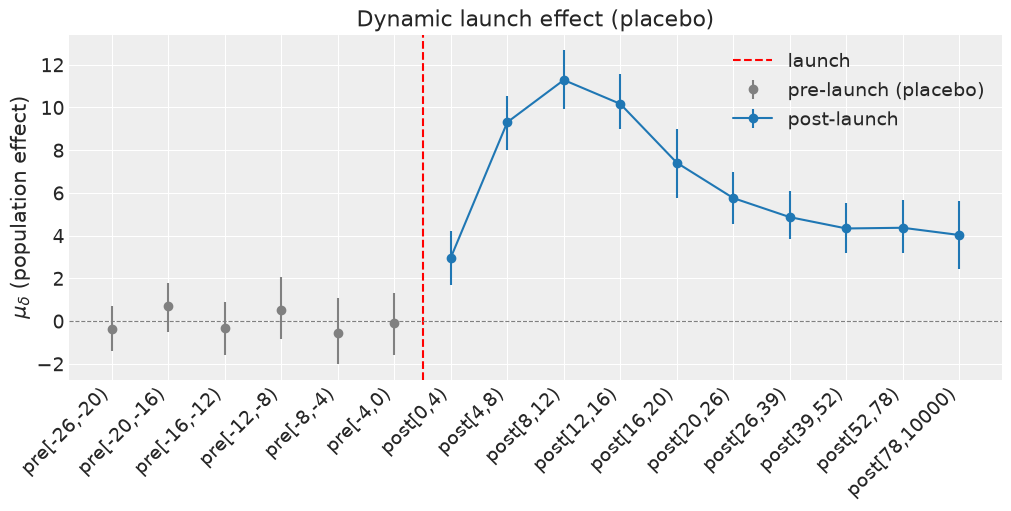

In [27]:
print("=== Same noise, NO anticipation (placebo check should PASS) ===")
result_placebo_ok.summary()
result_placebo_ok.plot();

### Model diagnostics

The underlying `HierarchicalITS` is a standard PyMC model, so we can use `pm.model_to_graphviz` to visualise the DAG, ArviZ trace plots to check convergence, and `az.summary` for R-hat / ESS diagnostics. These are essential sanity checks before trusting the causal estimates.

**Model graph** &mdash; the plate diagram shows the hierarchical structure: population hyperparameters at the top, per-unit parameters inside the "unit" plate, and the likelihood at the bottom.

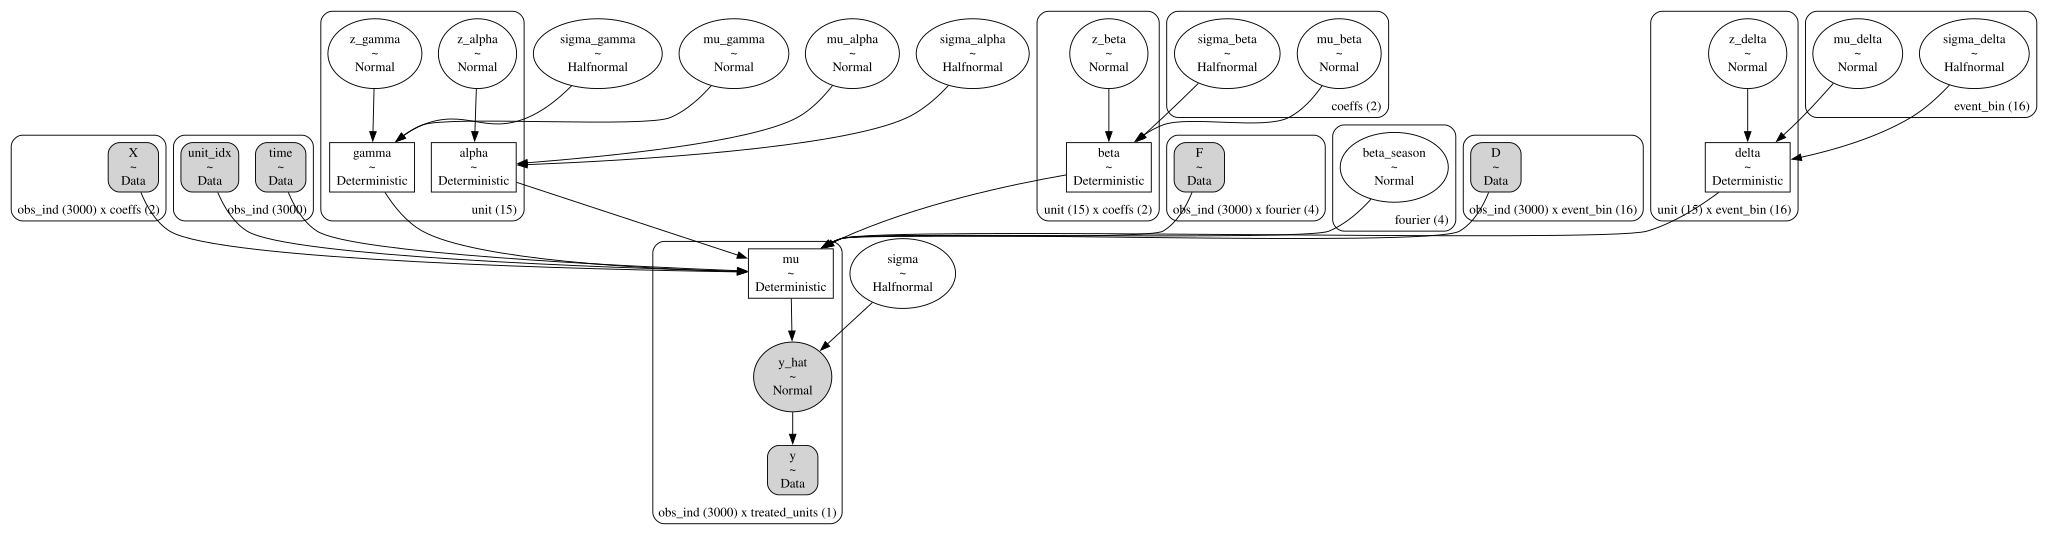

In [28]:
pm.model_to_graphviz(result_placebo_ok.model)

**Trace plots** &mdash; each row shows a population-level hyperparameter.
Look for: chains that overlap and appear stationary (good mixing), no
sustained trends, and no divergences flagged in the sampling output. The
right-hand marginal posteriors should be smooth and unimodal.

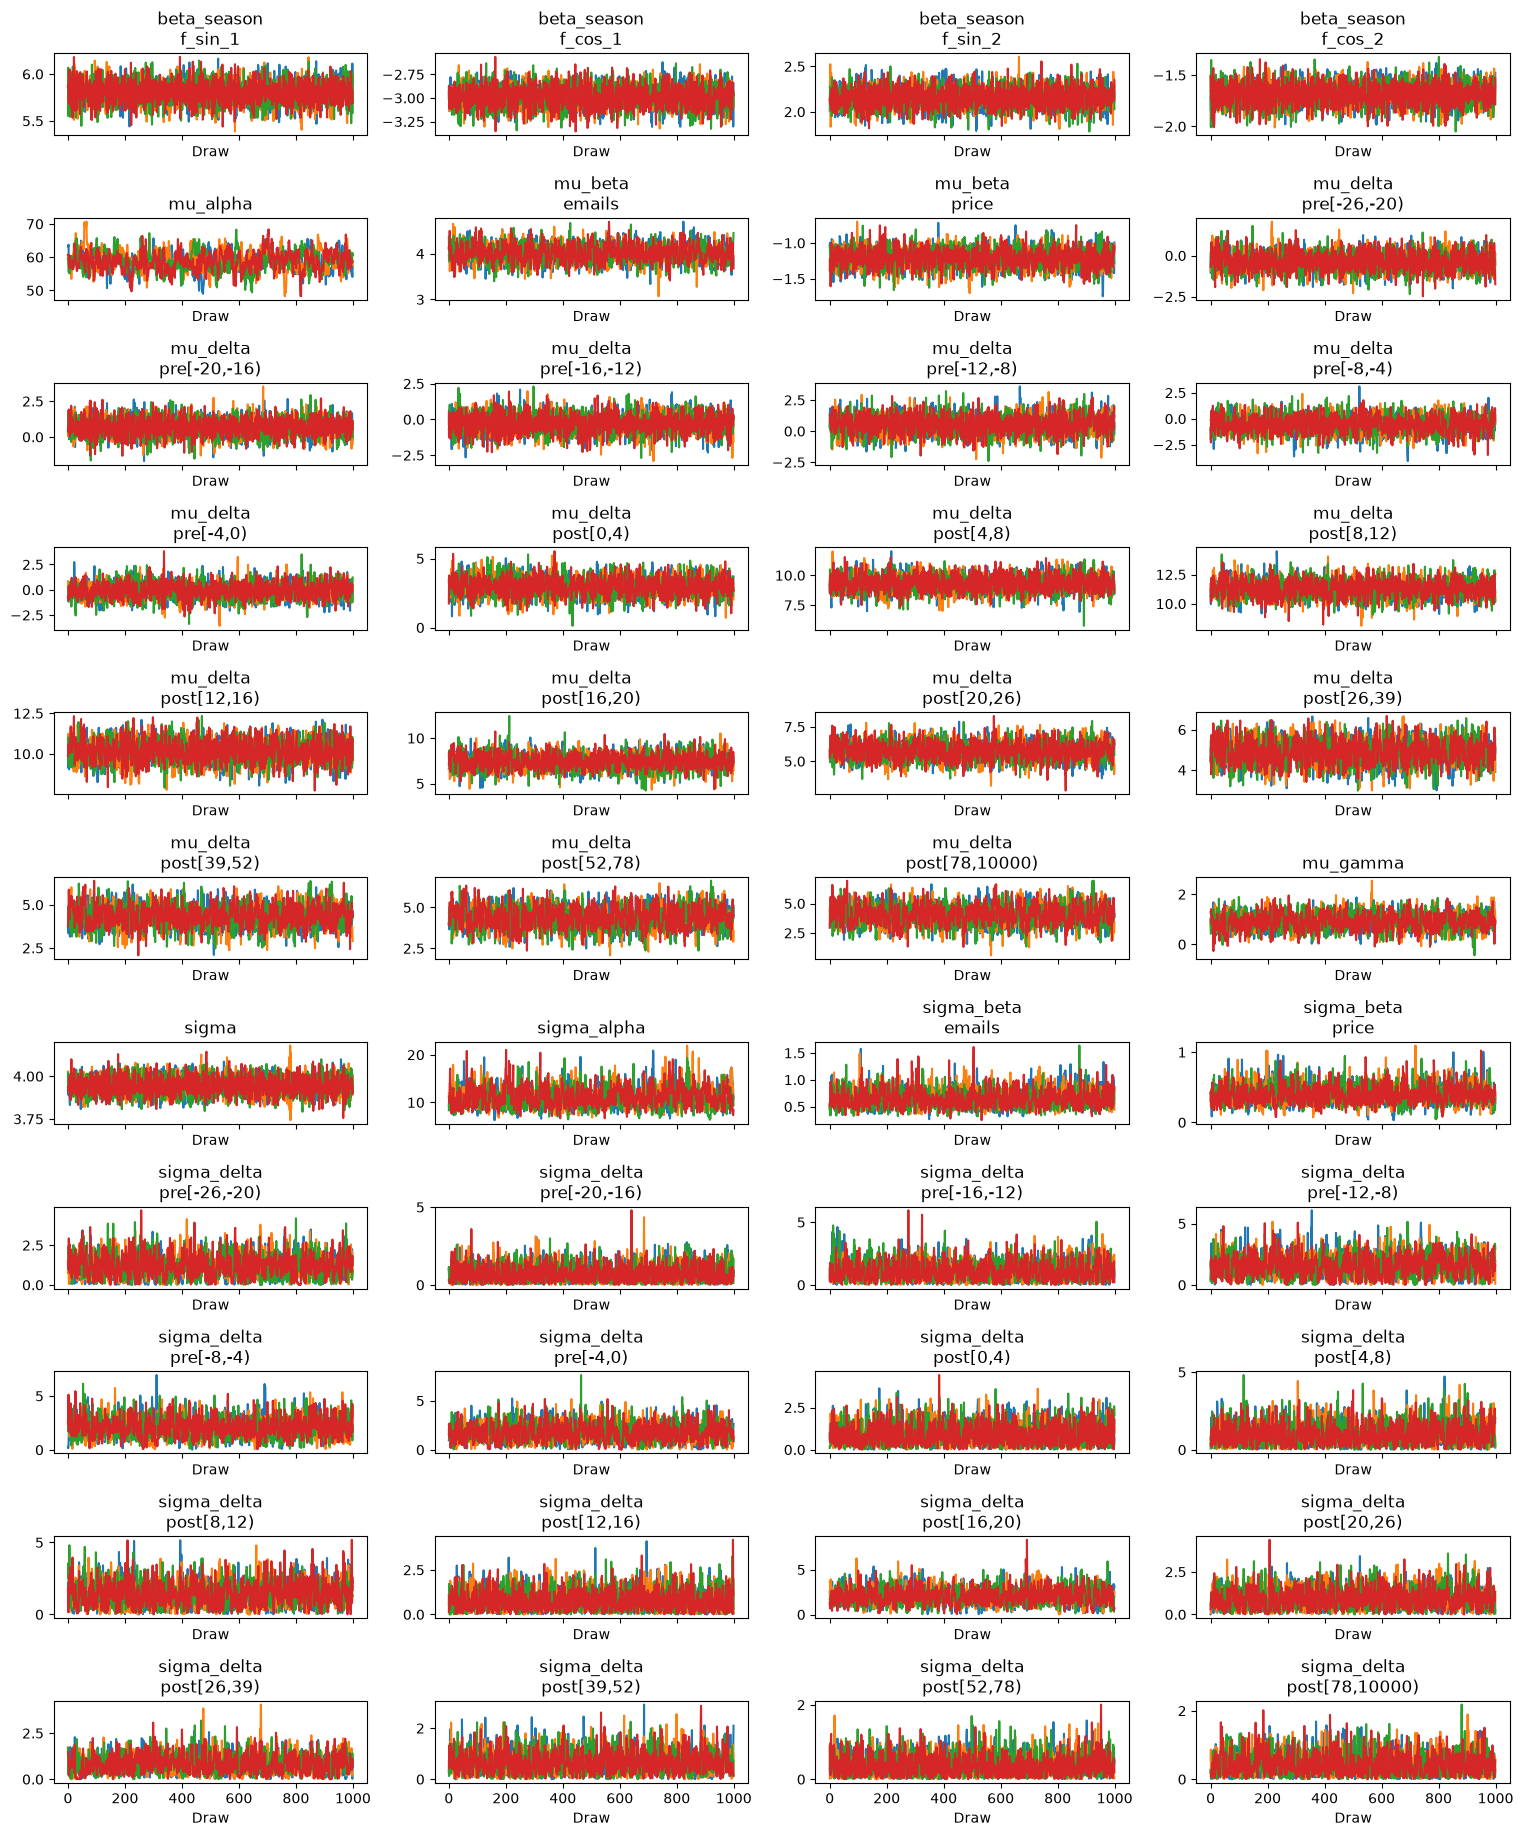

In [29]:
import arviz as az

# The per-bin hyperparameters give 44 panels, above ArviZ's default limit of 40.
with az.rc_context({"plot.max_subplots": 60}):
    az.plot_trace(
        result_placebo_ok.idata,
        var_names=[
            "beta_season",
            "mu_alpha",
            "mu_beta",
            "mu_delta",
            "mu_gamma",
            "sigma",
            "sigma_alpha",
            "sigma_beta",
            "sigma_delta",
        ],
    )
plt.gcf().tight_layout()
plt.show()

**Per-unit effect profiles** &mdash; each panel below shows one product's posterior `delta` coefficients across the 16 event-time bins (6 pre-launch placebos + 10 post-launch).

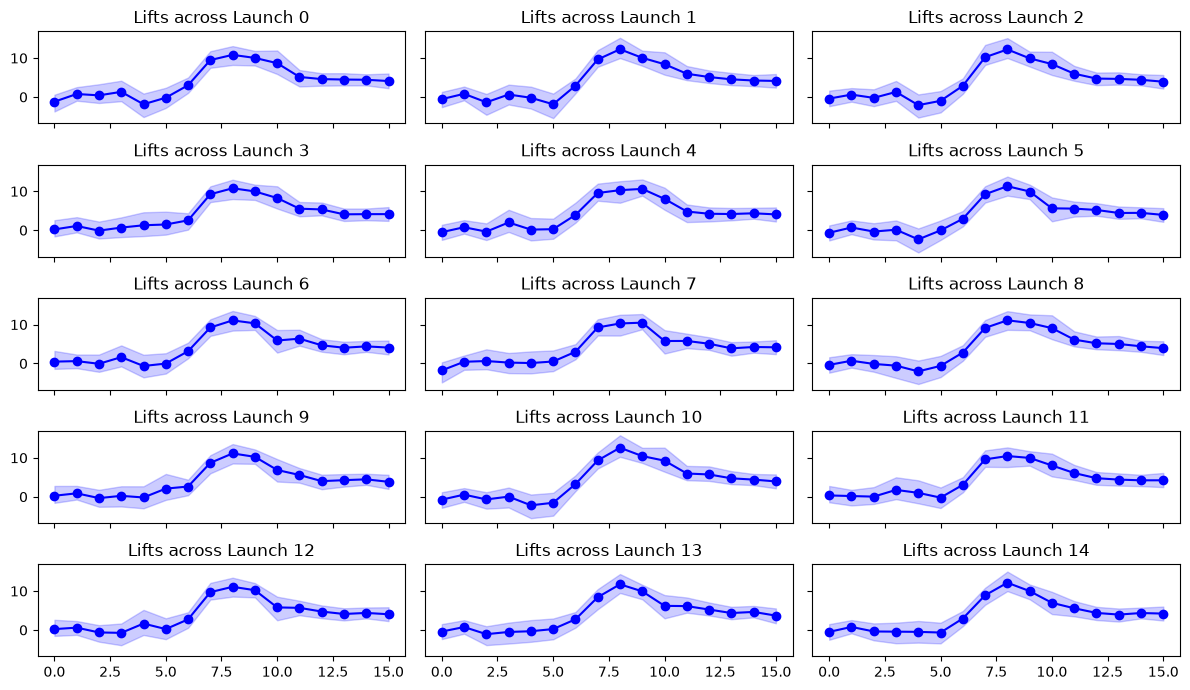

In [30]:
fig, axs = plt.subplots(5, 3, figsize=(12, 7), sharex=True, sharey=True)
# Per-unit delta draws: (chain, draw, unit, event_bin)
delta = result_placebo_ok.idata.posterior["delta"]
delta_mean = delta.mean(("chain", "draw"))
delta_lo, delta_hi = delta.quantile([0.03, 0.97], dim=("chain", "draw"))
bins = np.arange(delta.sizes["event_bin"])
for i, ax in enumerate(axs.flatten()):
    ax.plot(bins, delta_mean.isel(unit=i), marker="o", ls="-", color="blue")
    ax.fill_between(
        bins, delta_lo.isel(unit=i), delta_hi.isel(unit=i), color="blue", alpha=0.2
    )
    ax.set_title(f"Lifts across Launch {i}")
plt.tight_layout()
plt.show()

## AR(1) residuals (optional)

Time series residuals are rarely i.i.d. When autocorrelation is present, the default Normal noise can produce overconfident uncertainty intervals. Passing `ar_residuals=True` adds a **hierarchical AR(1)** process to the residuals, implemented via `pytensor.scan`:

$$
e_{i,t} = \rho_i \, e_{i,t-1} + \varepsilon_{i,t}, \qquad
\rho_i \sim \tanh\!\bigl(\mathcal{N}(\mu_\rho, \sigma_\rho)\bigr)
$$

The `tanh` link ensures stationarity ($|\rho_i| < 1$). This requires a **balanced panel**: every product observed at the same evenly spaced weeks, with no gaps.

:::{note}
With strong persistence ($\rho$ near 1) the long-run level of a *gradually* building effect is weakly identified and can trade off against the unit trends. In simulations with $\rho = 0.9$ and a ramp-shaped effect, the event-study variant understated the average effect by about a third, while step lifts (as below) and the saturation curve were recovered. Switching AR off overstated all three, so it is not a remedy.
:::

In [31]:
result_ar = cp.HierarchicalInterruptedTimeSeries(
    data=df_instant,
    formula="sales ~ 0 + emails + price",
    unit_col="product",
    time_col="week_idx",
    treatment_time_col="launch_week",
    effect_type="instant",
    seasonality={"period": 52, "K": 2},
    ar_residuals=True,
    model=HierarchicalITS(
        sample_kwargs={
            "draws": 1000,
            "tune": 1500,
            "chains": 4,
            "target_accept": 0.95,
            "random_seed": 42,
            "progressbar": False,
        }
    ),
).fit()

Initializing NUTS using jitter+adapt_diag...


Multiprocess sampling (4 chains in 4 jobs)


NUTS: [mu_alpha, sigma_alpha, z_alpha, mu_gamma, sigma_gamma, z_gamma, mu_beta, sigma_beta, z_beta, beta_season, mu_lift, sigma_lift, z_lift, mu_rho, sigma_rho, z_rho, z_ar, sigma_ar, sigma]


Sampling 4 chains for 1_500 tune and 1_000 draw iterations (6_000 + 4_000 draws total) took 57 seconds.


There were 10 divergences after tuning. Increase `target_accept` or reparameterize.


The rhat statistic is larger than 1.01 for some parameters. This indicates problems during sampling. See https://arxiv.org/abs/1903.08008 for details


... (3 outputs left out)

Sampling: [y_hat]


Sampling: [beta_season, mu_alpha, mu_beta, mu_gamma, mu_lift, mu_rho, sigma, sigma_alpha, sigma_ar, sigma_beta, sigma_gamma, sigma_lift, sigma_rho, y_hat, z_alpha, z_ar, z_beta, z_gamma, z_lift, z_rho]


Sampling: [y_hat]


Sampling: [y_hat]


Hierarchical ITS (staggered launch)
Formula: sales ~ 0 + emails + price
Effect type: instant
Units: 15
E[mu_lift] = 11.2   E[sigma_lift] = 2.63


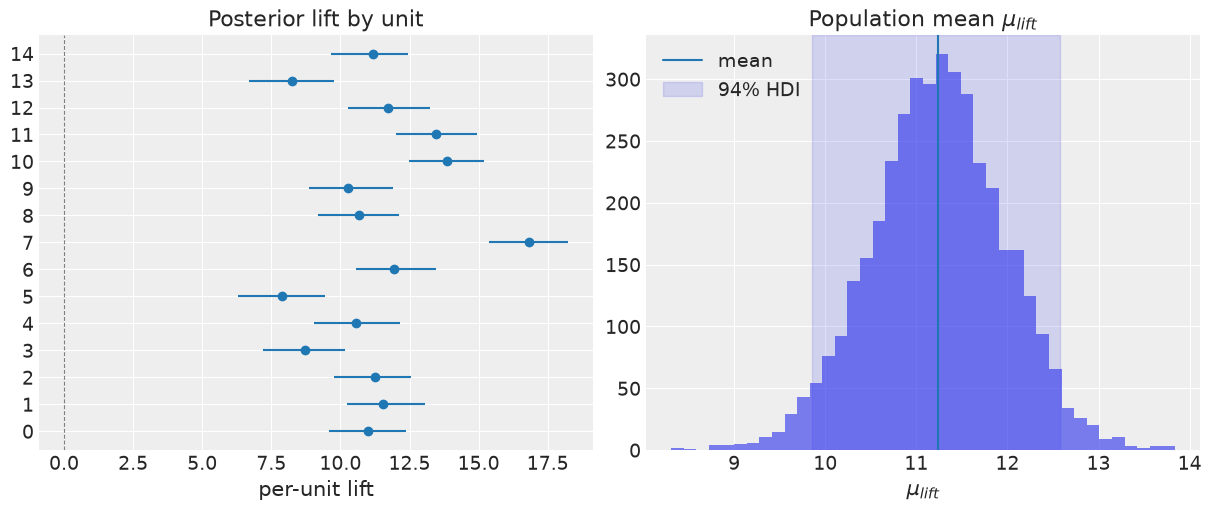

In [32]:
result_ar.summary()
result_ar.plot();

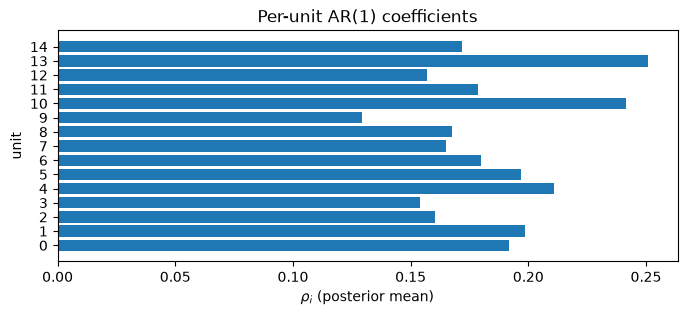

In [33]:
post_ar = result_ar.model.idata.posterior
rho_mean = post_ar["rho"].mean(("chain", "draw")).values
fig, ax = plt.subplots(figsize=(8, 3))
ax.barh(range(len(rho_mean)), rho_mean)
ax.set_yticks(range(len(rho_mean)))
ax.set_xlabel(r"$\rho_i$ (posterior mean)")
ax.set_ylabel("unit")
ax.set_title("Per-unit AR(1) coefficients")
ax.axvline(0, color="grey", lw=0.5)
plt.show()

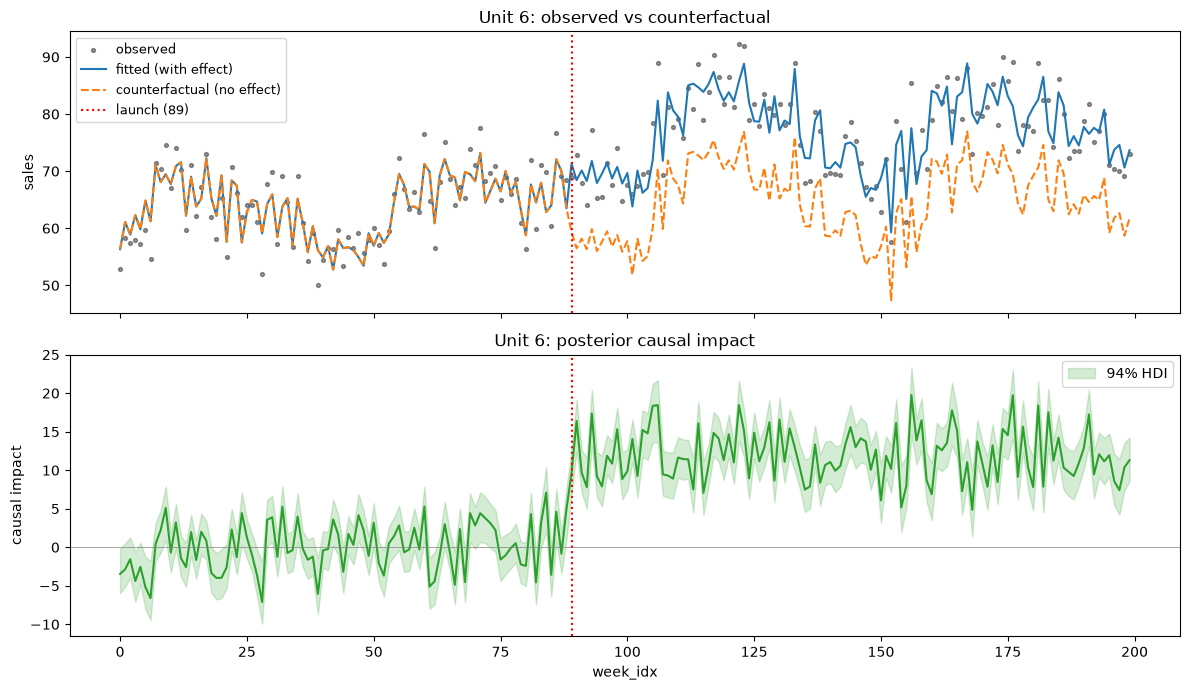

In [34]:
result_ar.plot_unit(unit_id=6)
plt.show()

## Calendar effects: shocks common to all launches

Each product is an interrupted time series normalised to its own launch: the effect is measured in event time, which is what makes launches comparable and lets their lifts be pooled. The baseline, though, lives in **calendar time**. That is why the data should be prepared on one shared calendar index spanning the whole study window (here `week_idx`, potentially several years in practice), with pre-launch history for every product: seasonality and unit trends are defined on that clock.

On its own, this design is pooled ITS. The jump at each launch is identified by the interruption, but a market-wide shock (a competitor entering, a demand surge, a pricing change) that hits every product at the same calendar weeks is not absorbed by anything except covariates and seasonality, so it leaks into the launch effect of whichever products had already launched.

Passing `calendar_effects=True` adds one shared random walk over calendar weeks to every product's baseline, kept in the counterfactual. Staggered launches make it identifiable: at any calendar week some products are still pre-launch, and their sales say what the market was doing that week, much like the not-yet-treated comparison in a staggered difference-in-differences. `launch_overlap()` shows where that comparison exists. After the last launch every product is post-launch, so the calendar effect is separated from long-run launch effects only by its prior, and the experiment warns about it.

Below we add a temporary market-wide surge around week 100 to the instant-lift panel and fit with and without calendar effects.

In [35]:
# Where is the calendar effect identified by not-yet-launched products?
# Any experiment exposes this diagnostic; here we use the instant-lift fit,
# which shares the launch weeks of the panel simulated below.
overlap = result_instant.launch_overlap()

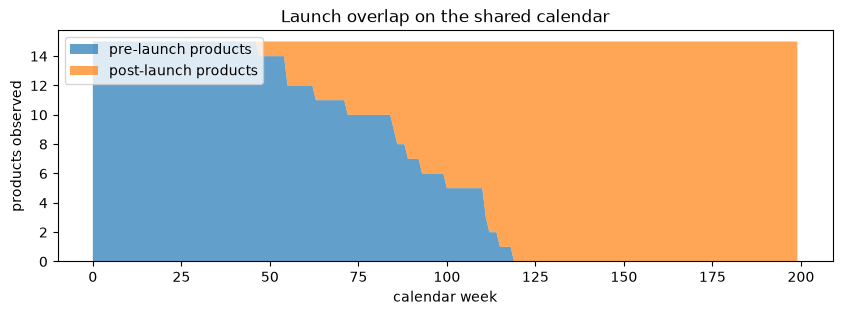

In [36]:
fig, ax = plt.subplots(figsize=(10, 3))
ax.stackplot(
    overlap.index,
    overlap["n_pre"],
    overlap["n_post"],
    labels=["pre-launch products", "post-launch products"],
    alpha=0.7,
)
ax.set_xlabel("calendar week")
ax.set_ylabel("products observed")
ax.set_title("Launch overlap on the shared calendar")
ax.legend(loc="upper left")
plt.show()

In [37]:
overlap[~overlap["identified"]].head()

,n_pre,n_post,identified
week_idx,,,
119,0,15,False
120,0,15,False
121,0,15,False
122,0,15,False
123,0,15,False


In [38]:
def market_shock(week):
    """A temporary market-wide demand surge around calendar week 100."""
    week = np.asarray(week, dtype=float)
    return 8.0 * np.exp(-(((week - 100.0) / 8.0) ** 2))


# Same instant-lift panel as before, plus a shock that hits every product at
# the same calendar weeks, whatever its launch date.
df_shock = simulate_panel(instant_effect, seed=0)
df_shock["sales"] = df_shock["sales"] + market_shock(df_shock["week_idx"])

post_rows = df_shock["week_idx"] >= df_shock["launch_week"]
true_avg_effect = _lift_i[df_shock.loc[post_rows, "product"]].mean()

shock_kwargs = {
    "data": df_shock,
    "formula": "sales ~ 0 + emails + price",
    "unit_col": "product",
    "time_col": "week_idx",
    "treatment_time_col": "launch_week",
    "effect_type": "instant",
    "seasonality": {"period": 52, "K": 2},
}


def make_shock_model():
    return HierarchicalITS(
        sample_kwargs={
            "draws": 1000,
            "tune": 1500,
            "chains": 4,
            "target_accept": 0.95,
            "random_seed": 42,
            "progressbar": False,
        }
    )


result_no_cal = cp.HierarchicalInterruptedTimeSeries(
    model=make_shock_model(), **shock_kwargs
).fit()
result_cal = cp.HierarchicalInterruptedTimeSeries(
    model=make_shock_model(), calendar_effects=True, **shock_kwargs
).fit()

Initializing NUTS using jitter+adapt_diag...


Multiprocess sampling (4 chains in 4 jobs)


NUTS: [mu_alpha, sigma_alpha, z_alpha, mu_gamma, sigma_gamma, z_gamma, mu_beta, sigma_beta, z_beta, beta_season, mu_lift, sigma_lift, z_lift, sigma]


Sampling 4 chains for 1_500 tune and 1_000 draw iterations (6_000 + 4_000 draws total) took 27 seconds.


The rhat statistic is larger than 1.01 for some parameters. This indicates problems during sampling. See https://arxiv.org/abs/1903.08008 for details


Sampling: [y_hat]


... (14 outputs left out)

Sampling: [y_hat]


Sampling: [beta_season, mu_alpha, mu_beta, mu_gamma, mu_lift, sigma, sigma_alpha, sigma_beta, sigma_calendar, sigma_gamma, sigma_lift, y_hat, z_alpha, z_beta, z_calendar, z_gamma, z_lift]


Sampling: [y_hat]


Sampling: [y_hat]


In [39]:
result_cal.summary()

Hierarchical ITS (staggered launch)
Formula: sales ~ 0 + emails + price
Effect type: instant
Units: 15
Calendar effects: on   E[sigma_calendar] = 7.07
E[mu_lift] = 10.9   E[sigma_lift] = 2.69


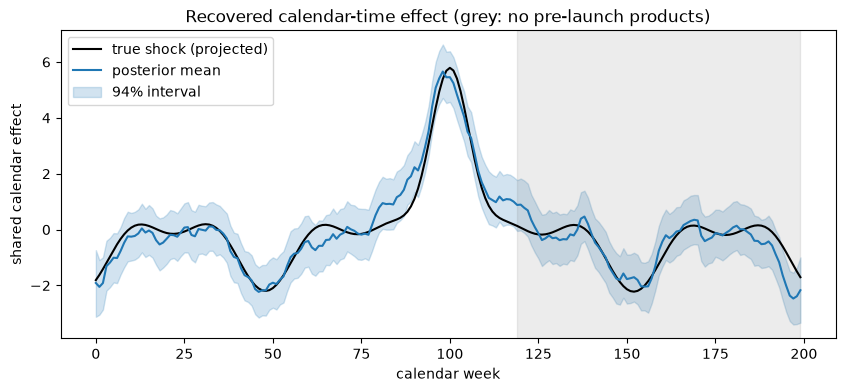

In [40]:
# The calendar effect is projected off the intercept, linear trend and
# seasonal span, so compare it with the true shock after the same projection.
cal = result_cal.idata.posterior["calendar_effect"]
cal_mean = cal.mean(("chain", "draw")).values
cal_lo, cal_hi = np.percentile(
    cal.stack(sample=("chain", "draw")).values, [3, 97], axis=-1
)
grid = cal.coords["calendar_time"].values
true_projected = result_cal._calendar_projection @ market_shock(grid)

fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(grid, true_projected, color="black", label="true shock (projected)")
ax.plot(grid, cal_mean, color="C0", label="posterior mean")
ax.fill_between(grid, cal_lo, cal_hi, color="C0", alpha=0.2, label="94% interval")
unidentified = overlap.index[~overlap["identified"]]
ax.axvspan(unidentified.min(), unidentified.max(), color="grey", alpha=0.15)
ax.set_xlabel("calendar week")
ax.set_ylabel("shared calendar effect")
ax.set_title("Recovered calendar-time effect (grey: no pre-launch products)")
ax.legend()
plt.show()

In [41]:
print(f"True average post-launch effect: {true_avg_effect:.2f}")
print("Without calendar effects:")
display(result_no_cal.effect_summary(cumulative=False, relative=False).table)
print("With calendar effects:")
display(result_cal.effect_summary(cumulative=False, relative=False).table)

True average post-launch effect: 11.24
Without calendar effects:


,mean,median,hdi_lower,hdi_upper,p_gt_0
average,11.906873,11.910308,11.342593,12.461737,1.0


With calendar effects:


,mean,median,hdi_lower,hdi_upper,p_gt_0
average,10.713628,10.712945,10.096056,11.32426,1.0


The calendar term recovers the shape of the shock closely (after removing its mean, linear trend and seasonal components, which the projection assigns to the intercept, trends and Fourier terms instead), with the widest uncertainty in the shaded weeks after the last launch.

The effect summaries show what is and is not fixed. Without calendar effects, the surge is attributed to the products that were live during it and the average post-launch effect is pulled above the truth. With calendar effects that upward bias is removed, but in this example the estimate lands somewhat *below* the truth instead, with neither interval quite covering it. The most likely reason is the shaded region: after the last launch there is no not-yet-launched product left, so part of the long-run lift can be traded against the calendar effect and only the prior keeps them apart.

That is the practical lesson: calendar effects protect the estimate only where `launch_overlap()` shows pre-launch units. In real analyses, check the overlap and consider truncating the window to where `identified` is `True`, or treat late-window effects as resting on ITS extrapolation alone.

## Notes on the implementation

- All hierarchical parameters use a non-centered parametrization for sampler health.
- **Hierarchical linear time trends** $\gamma_i \sim \mathcal{N}(\mu_\gamma, \sigma_\gamma)$ are always included, allowing each unit's baseline to drift linearly over time. The time index is standardized internally for numerical stability.
- **Saturation (`effect_type='saturation'`)** replaces the instant level shift with a Hill curve, $\text{effect}_i(\tau) = L_i \, \tau^s / (k_i^s + \tau^s)$. The ceiling lift $L_i$ and half-saturation time $k_i$ are hierarchical per unit (log scale, non-centered); the Hill exponent $s$ is a single shared population parameter. $L_i > 0$, so the effect is assumed positive, and population summaries describe the median unit. `mu_logk`/`sigma_logk`/`s` use fixed, generic priors (not data-adaptive to `time_col`'s scale) — override them via `priors=` if your time index isn't in "a handful of periods to ramp up" units, e.g. daily rather than weekly data.
- **Optional AR(1) residuals** (`ar_residuals=True`) add per-unit autocorrelated noise via `pytensor.scan`. The AR coefficient is constrained to $(-1, 1)$ via a `tanh` link and partially pooled across units. Requires a balanced panel with evenly spaced times and no gaps. Under strong persistence, gradually building event-study effects are weakly identified (see the AR section).
- **Optional calendar effects** (`calendar_effects=True`) add one shared Gaussian random walk over the distinct calendar times, projected off the intercept, linear trend and seasonal terms so it cannot compete with them. Its scale prior `sigma_calendar` is the marginal standard deviation over the whole window. It is identified where `launch_overlap()` shows pre-launch units.
- `time_col` must be a shared calendar index for every unit; seasonality, trends and calendar effects are all defined on it, while effects are defined on event time `time_col - treatment_time_col`.
- Priors on population-level scale parameters are derived from the data via `priors_from_data` so the model is approximately scale-invariant.
- Covariates from the patsy formula are standardized internally; the hierarchical $\alpha$ takes the place of an intercept (you should not include one in `formula`). `print_coefficients()` also reports covariate coefficients back on their original (unstandardized) scale.
- Any prior can be overridden via the `priors=` argument to `HierarchicalITS` using the `pymc_extras.prior.Prior` system.